In [1]:
%load_ext autoreload
%autoreload 2

In [32]:
import os
import json

import sys

sys.path.append("../")

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "1,2,3,4,5,6"
##################################################################

import logging
from src.utils import logging_utils
from src.utils import env_utils, experiment_utils
import torch
import transformers
from rich.console import Console
from rich.theme import Theme
import nnsight
experiment_utils.set_seed(42)

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme, width = 300)


# Override print globally
def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)


logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")
logger.info(f"{nnsight.__version__}")

2026-02-26 14:08:14 src.utils.experiment_utils INFO     setting all seeds to 42


2026-02-26 14:08:14 __main__ INFO     torch.__version__='2.10.0+cu128', torch.version.cuda='12.8'
2026-02-26 14:08:14 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=6, torch.cuda.get_device_name()='NVIDIA A100 80GB PCIe'
2026-02-26 14:08:14 __main__ INFO     transformers.__version__='5.1.0'
2026-02-26 14:08:14 __main__ INFO     0.5.15


In [3]:
from src.models import ModelandTokenizer

# model_key = "allenai/Olmo-3-1125-32B"
# model_key = "allenai/Olmo-3.1-32B-Instruct"
# model_key = "allenai/Olmo-3.1-7B-RL-Zero-Code"

# model_key = "meta-llama/Llama-3.3-70B-Instruct"

# model_key = "deepseek-ai/deepseek-coder-33b-base"
# model_key = "deepseek-ai/DeepSeek-Coder-V2-Lite-Instruct"

# model_key = "openai/gpt-oss-20b"
# model_key = "openai/gpt-oss-120b" #! weird results. known issue.

# model_key = "Qwen/Qwen3-Coder-30B-A3B-Instruct"
# model_key = "Qwen/Qwen2.5-Coder-14B"
# model_key = "Qwen/Qwen2.5-Coder-14B-Instruct"
# model_key = "Qwen/Qwen2.5-Coder-32B"
model_key = "Qwen/Qwen2.5-Coder-32B-Instruct"
# model_key = "Qwen/Qwen2.5-72B"
# model_key = "Qwen/Qwen2.5-72B-Instruct"

# model_key = "bigcode/starcoder2-15b"

# model_key = "zai-org/GLM-4.7-Flash"

mt = ModelandTokenizer(
    model_key=model_key,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)

2026-02-26 13:40:17 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-02-26 13:40:17 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-02-26 13:40:17 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f8697edf290>
2026-02-26 13:40:17 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7f8697e81f50> server_hostname='huggingface.co' timeout=10
2026-02-26 13:40:17 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f86988f0a10>
2026-02-26 13:40:17 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-02-26 13:40:17 httpcore.http11 DEBUG    send_request_headers.complete
2026-02-26 13:40:17 http

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-02-26 13:40:41 httpcore.connection DEBUG    close.started
2026-02-26 13:40:41 httpcore.connection DEBUG    close.complete
2026-02-26 13:40:41 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-02-26 13:40:41 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f8694af1c40>
2026-02-26 13:40:41 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7f8697e81f50> server_hostname='huggingface.co' timeout=10
2026-02-26 13:40:41 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f8697e8e690>
2026-02-26 13:40:41 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-02-26 13:40:41 httpcore.http11 DEBUG    send_request_headers.complete
2026-02-26 13:40:41 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

In [4]:
from src.goals.eval import run_evaluation, pretty_print_eval_results
from src.goals.data import IncompleteCodeDataset
from src.tokens import prepare_input
from src.goals.data import CodeGenerations, Code
from src.goals.functional import supports_chat_template, apply_chat_template
from src.functional import generate_with_patch


SAMPLE_IDX = 5

eval_dataset = IncompleteCodeDataset.load_dataset()
print(eval_dataset[SAMPLE_IDX])

sample = eval_dataset[SAMPLE_IDX]
instruction = sample.instruction
unfinished_code = sample.code
function_name = sample.function_name or "func"
unit_tests = sample.unit_tests
prefills = []
for ptype, pfill_list in sample.prefills.items():
    prefills.extend([prefill, ptype] for prefill in pfill_list)


if supports_chat_template(mt):
    prompts = [
        apply_chat_template(
            mt=mt,
            user_query=instruction.strip(),
            incomplete_code=unfinished_code + prefill,
        )
        for prefill, ptype in prefills
    ]
else:
    prompts = [
        instruction + "<code>" + unfinished_code + prefill
        for (prefill, ptype) in prefills
    ]


inputs = prepare_input(
    prompts=prompts,
    tokenizer=mt,
)

output = generate_with_patch(
    mt=mt,
    inputs=inputs,
    n_gen_per_prompt=1,
    max_new_tokens=64,
    do_sample=False,
    remove_prefix=True,
)

results = CodeGenerations(
    sample=sample,
    generations=[
        Code(prefill=prefill, prefill_type=ptype, full_prompt=inp, lm_generation=out)
        for (prefill, ptype), inp, out in zip(prefills, prompts, output)
    ],
)

# print(f"[white]{str(results)}[/white]")

eval_results = run_evaluation(
    result = results,
    function_name=function_name,
    code_stop_tag="</code>",
)

# Print results in tabular format
pretty_print_eval_results(eval_results)

2026-02-26 13:40:44 src.goals.data INFO     Loaded 14 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


Instruction: Write a function in python that checks if a string is a palindrome.


def is_palindrome(s: str) -> bool:
    return True if 
Unit Tests: [('racecar', True), ('hello', False), ('', True), ('a', True), ('ab', False), ('aba', True), ('abba', True)]
Prefills: {
  "aligned": [
    "",
    "(",
    "s",
    "s ==",
    "s == s",
    "s[::",
    "s[::-1]",
    "(s",
    "list(",
    "list(s)"
  ],
  "adversarial": [
    "not",
    "not (",
    "s +",
    "3",
    "1 +"
  ],
  "inconsequential": [
    "bool(",
    "True and",
    "False or",
    "0 +"
  ]
}
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False


"""def is_palindrome(s: str) -> bool:
    return True if """

                                                                                Code Completion Results                                                                                
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Prefill                     ┃ Logic                                                          ┃ Verdict ┃ Unit Tests ┃ Logs                                                          ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ aligned: ""                 │ " s == s[::-1] else False                                      │ PASSED  │            │                                                               │
│                             │                                                                │         │            │                                                               │
│                             │ # Example usage:                                               │         │            │                                                               │
│                             │ print(is_palindrome("racecar"))  # Output: True                │         │            │                                                               │
│                             │ print(is_palindrome("hello"))    # Output: False"              │         │            │                                                               │
├─────────────────────────────┼────────────────────────────────────────────────────────────────┼─────────┼────────────┼───────────────────────────────────────────────────────────────┤
│ aligned: "("                │ "(s == s[::-1]) else False                                     │ PASSED  │            │                                                               │
│                             │                                                                │         │            │                                                               │
│                             │ # Example usage:                                               │         │            │                                                               │
│                             │ print(is_palindrome("racecar"))  # Output: True                │         │            │                                                               │
│                             │ print(is_palindrome("hello"))    # Output: False"              │         │            │                                                               │
├─────────────────────────────┼────────────────────────────────────────────────────────────────┼─────────┼────────────┼───────────────────────────────────────────────────────────────┤
│ aligned: "s"                │ "s == s[::-1] else False                                       │ PASSED  │            │                                                               │
│                             │                                                                │         │            │                                                               │
│                             │ # Example usage:                                               │         │            │                                                               │
│                             │ print(is_palindrome("racecar"))  # Output: True                │         │            │                                                               │
│                             │ print(is_palindrome("hello"))    # Output: False"              │         │            │                                                               │
├─────────────────────────────┼────────────────────────────────────────────────────────────────┼─────────┼────────────┼─────────────────

Summary: 17/19 passed, 2/19 failed

## Expand MCTS Trees
<b style="color:orange;">TODO</b>: match exploration hparams with the `02_sampling.ipynb` notebook

In [ ]:
from dataclasses import dataclass, field
from dataclasses_json import DataClassJsonMixin
from typing import Any

from src.goals.sampling import MCTSResult

# @dataclass
# class MCTSResult(DataClassJsonMixin):
#     """
#     Results from a single MCTS search + evaluation + contrastive sampling.
#     Serializable via DataClassJsonMixin (.to_dict() / .from_dict()).
    
#     The MCTS tree itself is not serialized (MCTSNode objects are not JSON-friendly).
#     Instead, we store the contrastive pairs as text paths + outcome probs,
#     and optionally save the tree as HTML via search.save_tree().
#     """
#     # Identification
#     model_name: str = ""
#     sample_idx: int = 0
#     prefill: str = ""
#     prefill_type: str = ""
#     function_name: str = "func"
    
#     # Prompt info
#     prompt: str = ""                     # full prompt sent to LM
#     prefix: str = ""                     # sample.code + prefill (for eval)
    
#     # MCTS config & stats
#     mcts_config: dict[str, Any] = field(default_factory=dict)
#     mcts_stats: dict[str, Any] = field(default_factory=dict)
    
#     # Evaluation counts {"green": N, "orange": N, "red": N, "total": N}
#     eval_counts: dict[str, int] = field(default_factory=dict)
    
#     # Contrastive pairs: depth (str key) -> list of {pos_path, neg_path, pos_probs, neg_probs}
#     contrastive_pairs: dict[str, list[dict[str, Any]]] = field(default_factory=dict)
    
#     # Sampling thresholds used
#     sampling_config: dict[str, Any] = field(default_factory=dict)
    
#     def save(self, filepath: str) -> None:
#         os.makedirs(os.path.dirname(filepath), exist_ok=True)
#         with open(filepath, "w") as f:
#             json.dump(self.to_dict(), f, indent=2)
    
#     @classmethod
#     def load(cls, filepath: str) -> "MCTSResult":
#         with open(filepath, "r") as f:
#             return cls.from_dict(json.load(f))
    
#     @property
#     def total_pairs(self) -> int:
#         return sum(len(p) for p in self.contrastive_pairs.values())
    
#     @property
#     def depths_with_pairs(self) -> list[int]:
#         return sorted(int(d) for d in self.contrastive_pairs if self.contrastive_pairs[d])


# Quick test: round-trip serialization
_test = MCTSResult(model_name="test", sample_idx=0, prefill="x")
assert MCTSResult.from_dict(_test.to_dict()).model_name == "test"
print("MCTSResult serialization OK")

MCTSResult serialization OK

In [6]:
from src.goals.sampling import MCTSSearch
from src.goals.eval import evaluate_mcts_tree
from src.goals.probe import sample_multidepth_pairs, print_contrastive_pairs
from src.utils.env_utils import DEFAULT_RESULTS_DIR
from dataclasses import asdict

# --- Config ---
MCTS_ITERATIONS = 1500
MCTS_MAX_DEPTH = 20
MCTS_TOP_K = 10
MCTS_PROB_THRESHOLD = 0.01
DEPTH_FIRST = True

SAMPLING_CONFIG = dict(
    min_depth=1,
    max_depth=10,
    min_green_confidence=0.5,
    max_red_in_positive=0.3,
    min_red_confidence=0.5,
    max_green_in_negative=0.1,
    max_uncertain=0.5,
)

model_short_name = mt.name.split("/")[-1]
save_dir = os.path.join(DEFAULT_RESULTS_DIR, "probe", model_short_name, f"sample_{SAMPLE_IDX}")
mcts_dir = os.path.join(save_dir, "MCTS")
os.makedirs(save_dir, exist_ok=True)
os.makedirs(mcts_dir, exist_ok=True)
# --- Run MCTS + eval + contrastive sampling for each prefill ---
all_results: list[MCTSResult] = []

for prefill_idx, (prefill_val, prefill_type) in enumerate(prefills):
    _orig_print(f"\n{'='*60}")
    _orig_print(f"Prefill {prefill_idx}/{len(prefills)}: ({prefill_type}) {prefill_val!r}")
    _orig_print(f"{'='*60}")
    
    prompt = prompts[prefill_idx]
    prefix = sample.code + prefill_val
    
    # 1) MCTS search
    search = MCTSSearch(
        mt=mt,
        prompt=prompt,
        max_depth=MCTS_MAX_DEPTH,
        top_k=MCTS_TOP_K,
        prob_threshold=MCTS_PROB_THRESHOLD,
    )
    root = search.run(n_iterations=MCTS_ITERATIONS, depth_first=DEPTH_FIRST)
    
    # 2) Evaluate tree
    counts = evaluate_mcts_tree(
        root=search.root,
        prefix=prefix,
        unit_tests=sample.unit_tests,
        function_name=function_name,
        terminal_only=False,
    )
    _orig_print(f"  Eval counts: {counts}")
    
    # 3) Sample contrastive pairs
    pairs_by_depth = sample_multidepth_pairs(root=search.root, **SAMPLING_CONFIG)
    n_pairs = sum(len(p) for p in pairs_by_depth.values())
    _orig_print(f"  Contrastive pairs: {n_pairs}")
    
    # 4) Serialize contrastive pairs (MCTSNode -> text paths)
    serialized_pairs = {}
    for depth, pairs in pairs_by_depth.items():
        serialized_pairs[str(depth)] = [
            {
                "pos_path": pair.positive.get_path_text(),
                "neg_path": pair.negative.get_path_text(),
                "pos_probs": {"green": pair.pos_probs.green, "red": pair.pos_probs.red, "uncertain": pair.pos_probs.uncertain},
                "neg_probs": {"green": pair.neg_probs.green, "red": pair.neg_probs.red, "uncertain": pair.neg_probs.uncertain},
            }
            for pair in pairs
        ]
    
    # 5) Build result
    result = MCTSResult(
        model_name=model_short_name,
        sample_idx=SAMPLE_IDX,
        prefill=prefill_val,
        prefill_type=prefill_type,
        function_name=function_name,
        prompt=prompt,
        prefix=prefix,
        mcts_config=dict(
            iterations=MCTS_ITERATIONS, max_depth=MCTS_MAX_DEPTH,
            top_k=MCTS_TOP_K, prob_threshold=MCTS_PROB_THRESHOLD,
            depth_first=DEPTH_FIRST,
        ),
        mcts_stats=search.get_stats(),
        eval_counts=counts,
        contrastive_pairs=serialized_pairs,
        sampling_config=SAMPLING_CONFIG,
    )
    all_results.append(result)
    
    # 6) Save to disk
    safe_prefill_name = prefill_val.replace(" ", "_").replace("/", "_") or "empty"
    result_path = os.path.join(mcts_dir, f"prefill_{prefill_idx}_{safe_prefill_name}.json")
    result.save(result_path)
    
    # Also save tree HTML
    tree_path = os.path.join(mcts_dir, f"prefill_{prefill_idx}_{safe_prefill_name}_tree.html")
    search.save_tree(tree_path, show_colors=True)

print(f"\n[bold]Done! Saved {len(all_results)} results to {mcts_dir}[/bold]")
print(f"Total contrastive pairs across all prefills: {sum(r.total_pairs for r in all_results)}")


Prefill 0/19: (aligned) ''
2026-02-16 13:50:54 src.goals.sampling DEBUG    MCTS iteration 50/1500, total nodes: 35
2026-02-16 13:50:56 src.goals.sampling DEBUG    MCTS iteration 100/1500, total nodes: 56
2026-02-16 13:50:56 src.goals.sampling DEBUG    MCTS iteration 150/1500, total nodes: 56
2026-02-16 13:50:56 src.goals.sampling DEBUG    MCTS iteration 200/1500, total nodes: 56
2026-02-16 13:50:56 src.goals.sampling DEBUG    MCTS iteration 250/1500, total nodes: 56
2026-02-16 13:50:56 src.goals.sampling DEBUG    MCTS iteration 300/1500, total nodes: 56
2026-02-16 13:50:56 src.goals.sampling DEBUG    MCTS iteration 350/1500, total nodes: 56
2026-02-16 13:50:56 src.goals.sampling DEBUG    MCTS iteration 400/1500, total nodes: 56
2026-02-16 13:50:56 src.goals.sampling DEBUG    MCTS iteration 450/1500, total nodes: 56
2026-02-16 13:50:56 src.goals.sampling DEBUG    MCTS iteration 500/1500, total nodes: 56
2026-02-16 13:50:56 src.goals.sampling DEBUG    MCTS iteration 550/1500, total node

Done! Saved 19 results to /disk/u/arnab/Codes/Projects/goals/results/probe/Qwen2.5-Coder-32B-Instruct/sample_5/MCTS

Total contrastive pairs across all prefills: 86526

## Load MCTS Trees

In [9]:
from src.goals.sampling import MCTSResult

mcts_dir = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "probe_test",
    model_key.split("/")[-1],
    f"sample_{SAMPLE_IDX}",
    "MCTS"
)
all_results_loaded = []
for filename in os.listdir(mcts_dir):
    if filename.endswith(".json"):
        filepath = os.path.join(mcts_dir, filename)
        loaded_result = MCTSResult.load(filepath)
        all_results_loaded.append(loaded_result)

all_results = all_results_loaded

logger.info(f"Loaded {len(all_results)} MCTS results from {mcts_dir}")

2026-02-19 15:11:04 __main__ INFO     Loaded 20 MCTS results from /disk/u/arnab/Codes/Projects/goals/results/probe_test/Qwen2.5-Coder-32B-Instruct/sample_0/MCTS


## Extract contrastive branches

In [10]:
@torch.inference_mode()
def get_last_token_latents_batch(
    mt: ModelandTokenizer,
    texts: list[str],
    layers: list[int] | None = None,
) -> dict[int, torch.Tensor]:
    """
    Extract residual stream hidden states at the last token position for a batch of inputs.
    
    Simplified and batched alternative to get_hs — no interventions, only grabs
    the last (non-padding) token's residual stream across specified layers.
    
    Each layer's output stays on its native GPU (no cross-device stacking).
    
    Args:
        mt: ModelandTokenizer instance
        texts: List of input strings
        layers: Layer indices to extract from. None = all layers.
    
    Returns:
        Dict mapping layer_idx -> Tensor of shape (batch, hidden_dim) on that layer's device.
    """
    if layers is None:
        layers = list(range(mt.n_layer))
    
    # Tokenize with left-padding so the last non-pad token is always at position -1
    inputs = prepare_input(prompts=texts, tokenizer=mt, padding_side="left")
    
    # Set up nnsight trace to capture layer outputs
    layer_saves = {}
    with mt.trace(inputs, scan=False):
        for layer_idx in layers:
            layer_name = mt.layer_name_format.format(layer_idx)
            module = mt
            for attr in layer_name.split("."):
                module = module[int(attr)] if attr.isdigit() else getattr(module, attr)
            output = module.output
            # Some architectures wrap output in a tuple
            if isinstance(output, tuple) or (hasattr(output, '__len__') and not hasattr(output, 'shape')):
                output = output[0]
            layer_saves[layer_idx] = output[:, -1, :].save()  # (batch, hidden_dim)
    
    # Return per-layer tensors, each staying on its native device
    return {l: layer_saves[l].float() for l in layers}


# Quick test
_test_hs = get_last_token_latents_batch(mt, [prompts[0], prompts[1]], layers=[0, mt.n_layer - 1])
for l, t in _test_hs.items():
    print(f"Layer {l}: shape={t.shape}, device={t.device}")
print(f"All layers for 1 input would give {mt.n_layer} tensors of shape (1, {mt.n_embd})")

Layer 0: shape=torch.Size([2, 5120]), device=cuda:0

Layer 63: shape=torch.Size([2, 5120]), device=cuda:7

All layers for 1 input would give 64 tensors of shape (1, 5120)

In [11]:
for prefill_idx, result in enumerate(all_results_loaded):
    _orig_print(f"\n{'='*60}")
    _orig_print(f"Contrastive pairs for prefill {prefill_idx} ({result.prefill_type}): {result.prefill!r}")
    for depth_str, pairs in result.contrastive_pairs.items():
        depth = int(depth_str)
        _orig_print(f"\n  Depth {depth} ({len(pairs)} pairs):")
    _orig_print(f"{'='*60}")


Contrastive pairs for prefill 0 (adversarial): '(3'

  Depth 3 (12 pairs):

  Depth 4 (19 pairs):

  Depth 5 (26 pairs):

  Depth 6 (25 pairs):

  Depth 7 (48 pairs):

  Depth 8 (72 pairs):

  Depth 9 (45 pairs):

  Depth 10 (32 pairs):

  Depth 11 (32 pairs):

  Depth 12 (21 pairs):

  Depth 13 (14 pairs):

  Depth 14 (14 pairs):

  Depth 15 (4 pairs):

  Depth 16 (4 pairs):

Contrastive pairs for prefill 1 (aligned): '(0'

Contrastive pairs for prefill 2 (aligned): '((1'

  Depth 2 (2 pairs):

  Depth 3 (4 pairs):

  Depth 4 (16 pairs):

  Depth 5 (24 pairs):

  Depth 6 (32 pairs):

  Depth 7 (32 pairs):

  Depth 8 (54 pairs):

  Depth 9 (54 pairs):

  Depth 10 (18 pairs):

  Depth 11 (26 pairs):

  Depth 12 (24 pairs):

  Depth 14 (7 pairs):

  Depth 15 (6 pairs):

  Depth 16 (3 pairs):

Contrastive pairs for prefill 3 (inconsequential): 'bool('

  Depth 1 (2 pairs):

  Depth 2 (15 pairs):

  Depth 3 (40 pairs):

  Depth 4 (54 pairs):

  Depth 5 (60 pairs):

  Depth 6 (60 pairs):



In [12]:
import random
from collections import Counter, defaultdict

# --- Config ---
UNIQUE_POSITIVE_SAMPLING = False  # If True, each unique positive node appears in only 1 pair
N_TRAIN_PAIRS = 10_000            # Max training pairs after split. None = use all available.
N_TEST_PAIRS = None               # Max test pairs after split. None = use all available.

# --- 1) Collect all contrastive pairs, tagged by prefill_idx ---

pair_records = []

for prefill_idx, result in enumerate(all_results):
    for depth_str, pairs in result.contrastive_pairs.items():
        for pair in pairs:
            pair_records.append({
                "prompt": result.prompt,
                "prefix": result.prefix,
                "pos_path": pair["pos_path"],
                "neg_path": pair["neg_path"],
                "depth": int(depth_str),
                "prefill_idx": prefill_idx,
                "prefill": result.prefill,
                "prefill_type": result.prefill_type,
            })

n_pairs_before_dedup = len(pair_records)
_orig_print(f"Total contrastive pair records (Cartesian product): {n_pairs_before_dedup}")

# --- 1b) Optional: unique positive sampling ---
# Each unique positive node (prefill_idx, pos_path) keeps only 1 randomly chosen pair.
# This prevents the same positive latent from appearing in multiple pairs.
if UNIQUE_POSITIVE_SAMPLING:
    random.seed(42)
    # Group pairs by (prefill_idx, pos_path)
    pos_groups: dict[tuple[int, str], list[int]] = defaultdict(list)
    for i, rec in enumerate(pair_records):
        pos_groups[(rec["prefill_idx"], rec["pos_path"])].append(i)
    
    # Keep one random pair per unique positive
    keep_indices = sorted(random.choice(indices) for indices in pos_groups.values())
    pair_records = [pair_records[i] for i in keep_indices]
    
    n_unique_pos = len(pos_groups)
    _orig_print(f"Unique positive sampling: {n_pairs_before_dedup} -> {len(pair_records)} pairs "
                f"({n_unique_pos} unique positive nodes, "
                f"{n_pairs_before_dedup / n_unique_pos:.1f}x avg Cartesian expansion)")

_orig_print(f"Pair records after dedup: {len(pair_records)}")

# Show distribution by depth
depth_counts = Counter(r["depth"] for r in pair_records)
for d in sorted(depth_counts):
    _orig_print(f"  Depth {d}: {depth_counts[d]} pairs")

# --- 2) Tree/prefill-level train/test split ---
# Reserve entire trees for test. At least 1 of each prefill type in test.
# Only consider prefills that have >0 contrastive pairs.

# Count pairs per prefill
pairs_per_prefill: dict[int, int] = Counter(r["prefill_idx"] for r in pair_records)

# Group prefill indices by type, only those with pairs
prefill_type_to_indices: dict[str, list[int]] = defaultdict(list)
for idx, result in enumerate(all_results):
    if pairs_per_prefill.get(idx, 0) > 0:
        prefill_type_to_indices[result.prefill_type].append(idx)

random.seed(42)
test_prefill_set: set[int] = set()
for ptype, indices in prefill_type_to_indices.items():
    if len(indices) == 0:
        _orig_print(f"  WARNING: no prefills with pairs for type '{ptype}', skipping")
        continue
    if len(indices) == 1:
        # Only 1 prefill with pairs for this type — must keep it for train
        _orig_print(f"  WARNING: only 1 prefill with pairs for type '{ptype}' (idx={indices[0]}), keeping in train")
        continue
    test_prefill_set.add(random.choice(indices))

train_prefill_set = set(range(len(all_results))) - test_prefill_set

# Build pair-level indices from the prefill-level split
train_idx = [i for i, rec in enumerate(pair_records) if rec["prefill_idx"] in train_prefill_set]
test_idx = [i for i, rec in enumerate(pair_records) if rec["prefill_idx"] in test_prefill_set]

# --- 2b) Cap training and test pairs ---
# Shuffle first to ensure variety across prefills/depths, then truncate.
random.seed(42)
random.shuffle(train_idx)
n_train_before_cap = len(train_idx)
if N_TRAIN_PAIRS is not None and len(train_idx) > N_TRAIN_PAIRS:
    train_idx = train_idx[:N_TRAIN_PAIRS]

random.seed(42)
random.shuffle(test_idx)
n_test_before_cap = len(test_idx)
if N_TEST_PAIRS is not None and len(test_idx) > N_TEST_PAIRS:
    test_idx = test_idx[:N_TEST_PAIRS]

# --- 2c) Filter pair_records to only used pairs ---
# This ensures the latent extraction cell only processes relevant pairs.
used_idx_set = set(train_idx) | set(test_idx)
used_idx_sorted = sorted(used_idx_set)

# Remap old indices -> new contiguous indices
old_to_new = {old: new for new, old in enumerate(used_idx_sorted)}
pair_records = [pair_records[i] for i in used_idx_sorted]
train_idx = sorted([old_to_new[i] for i in train_idx])
test_idx = sorted([old_to_new[i] for i in test_idx])
n_pairs_total = len(pair_records)

# --- Print split summary ---
_orig_print(f"\n{'='*60}")
_orig_print(f"Tree-level train/test split (no latent leakage)")
if UNIQUE_POSITIVE_SAMPLING:
    _orig_print(f"  + unique positive sampling (each pos node in 1 pair only)")
if N_TRAIN_PAIRS is not None:
    _orig_print(f"  + train cap: {N_TRAIN_PAIRS} (from {n_train_before_cap} available)")
else:
    _orig_print(f"  + train cap: None (using all {n_train_before_cap} available)")
if N_TEST_PAIRS is not None:
    _orig_print(f"  + test cap:  {N_TEST_PAIRS} (from {n_test_before_cap} available)")
else:
    _orig_print(f"  + test cap:  None (using all {n_test_before_cap} available)")
_orig_print(f"{'='*60}")
_orig_print(f"Train prefills ({len(train_prefill_set)}):")
for idx in sorted(train_prefill_set):
    r = all_results[idx]
    n = pairs_per_prefill.get(idx, 0)
    _orig_print(f"  [{idx:>2}] ({r.prefill_type:>16}) {r.prefill!r:<15} -> {n} pairs")

_orig_print(f"Test prefills ({len(test_prefill_set)}):")
for idx in sorted(test_prefill_set):
    r = all_results[idx]
    n = pairs_per_prefill.get(idx, 0)
    _orig_print(f"  [{idx:>2}] ({r.prefill_type:>16}) {r.prefill!r:<15} -> {n} pairs")

_orig_print(f"\nTrain pairs: {len(train_idx)}, Test pairs: {len(test_idx)}")
_orig_print(f"Total pairs for latent extraction: {n_pairs_total} (was {n_pairs_before_dedup} before filtering)")
if len(test_idx) == 0:
    _orig_print("WARNING: 0 test pairs! All prefill types may have <=1 prefill with pairs.")

Total contrastive pair records (Cartesian product): 15658
Pair records after dedup: 15658
  Depth 1: 20 pairs
  Depth 2: 171 pairs
  Depth 3: 608 pairs
  Depth 4: 999 pairs
  Depth 5: 1301 pairs
  Depth 6: 1561 pairs
  Depth 7: 1733 pairs
  Depth 8: 1947 pairs
  Depth 9: 2147 pairs
  Depth 10: 1710 pairs
  Depth 11: 1175 pairs
  Depth 12: 1078 pairs
  Depth 13: 576 pairs
  Depth 14: 284 pairs
  Depth 15: 220 pairs
  Depth 16: 128 pairs

Tree-level train/test split (no latent leakage)
  + train cap: 10000 (from 3562 available)
  + test cap:  None (using all 12096 available)
Train prefills (17):
  [ 0] (     adversarial) '(3'            -> 368 pairs
  [ 1] (         aligned) '(0'            -> 0 pairs
  [ 2] (         aligned) '((1'           -> 302 pairs
  [ 4] (     adversarial) '1 +'           -> 884 pairs
  [ 5] (     adversarial) 'not (1'        -> 541 pairs
  [ 7] ( inconsequential) 'False or'      -> 43 pairs
  [ 8] (         aligned) '1 =='          -> 20 pairs
  [ 9] (     adver

## Extract Latents of the contrastive branches

In [13]:
# --- Extract latents for used contrastive pairs only (batched) ---
# pair_records has already been filtered to only train + test pairs (step 2c).
# For each pair, we feed prompt + pos_path and prompt + neg_path,
# extract hidden states at last token position for all layers.
# Latents are stored per-layer, each on its native GPU.

LAYERS_TO_PROBE = list(range(mt.n_layer))  # all layers; narrow down later
BATCH_SIZE = 32  # number of texts per forward pass (adjust based on GPU memory)

# Build flat list of all texts to process
pos_texts = [rec["prompt"] + rec["pos_path"] for rec in pair_records]
neg_texts = [rec["prompt"] + rec["neg_path"] for rec in pair_records]
all_texts = pos_texts + neg_texts  # 2 * n_pairs_total texts

n_total = len(all_texts)
_orig_print(f"Extracting latents for {n_total} texts ({n_pairs_total} pairs) in batches of {BATCH_SIZE}...")
_orig_print(f"  (train: {len(train_idx)}, test: {len(test_idx)})")

# Accumulate per-layer: layer_idx -> list of (batch_size, hidden_dim) tensors
latents_by_layer: dict[int, list[torch.Tensor]] = {l: [] for l in LAYERS_TO_PROBE}

for batch_start in range(0, n_total, BATCH_SIZE):
    batch_texts = all_texts[batch_start : batch_start + BATCH_SIZE]
    if batch_start % (BATCH_SIZE * 10) == 0:
        _orig_print(f"  Batch {batch_start // BATCH_SIZE + 1}/{(n_total + BATCH_SIZE - 1) // BATCH_SIZE}...")
    
    batch_hs = get_last_token_latents_batch(mt, batch_texts, layers=LAYERS_TO_PROBE)
    for l in LAYERS_TO_PROBE:
        latents_by_layer[l].append(batch_hs[l])

# Concatenate per-layer: layer_idx -> (2*n_pairs_total, hidden_dim) on that layer's device
# Then split into pos/neg per layer
Z_pos_by_layer: dict[int, torch.Tensor] = {}  # layer -> (n_pairs_total, hidden_dim)
Z_neg_by_layer: dict[int, torch.Tensor] = {}  # layer -> (n_pairs_total, hidden_dim)

for l in LAYERS_TO_PROBE:
    all_l = torch.cat(latents_by_layer[l], dim=0)  # (2*n_pairs_total, hidden_dim), same device
    Z_pos_by_layer[l] = all_l[:n_pairs_total]
    Z_neg_by_layer[l] = all_l[n_pairs_total:]

del latents_by_layer  # free the intermediate lists

# Print summary
_sample_layer = LAYERS_TO_PROBE[0]
print(f"Per-layer tensors: {len(Z_pos_by_layer)} layers")
print(f"  Layer {_sample_layer}: Z_pos {Z_pos_by_layer[_sample_layer].shape} on {Z_pos_by_layer[_sample_layer].device}")
_last_layer = LAYERS_TO_PROBE[-1]
print(f"  Layer {_last_layer}: Z_pos {Z_pos_by_layer[_last_layer].shape} on {Z_pos_by_layer[_last_layer].device}")

Extracting latents for 31316 texts (15658 pairs) in batches of 32...
  (train: 3562, test: 12096)
  Batch 1/979...
  Batch 11/979...
  Batch 21/979...
  Batch 31/979...
  Batch 41/979...
  Batch 51/979...
  Batch 61/979...
  Batch 71/979...
  Batch 81/979...
  Batch 91/979...
  Batch 101/979...
  Batch 111/979...
  Batch 121/979...
  Batch 131/979...
  Batch 141/979...
  Batch 151/979...
  Batch 161/979...
  Batch 171/979...
  Batch 181/979...
  Batch 191/979...
  Batch 201/979...
  Batch 211/979...
  Batch 221/979...
  Batch 231/979...
  Batch 241/979...
  Batch 251/979...
  Batch 261/979...
  Batch 271/979...
  Batch 281/979...
  Batch 291/979...
  Batch 301/979...
  Batch 311/979...
  Batch 321/979...
  Batch 331/979...
  Batch 341/979...
  Batch 351/979...
  Batch 361/979...
  Batch 371/979...
  Batch 381/979...
  Batch 391/979...
  Batch 401/979...
  Batch 411/979...
  Batch 421/979...
  Batch 431/979...
  Batch 441/979...
  Batch 451/979...
  Batch 461/979...
  Batch 471/979...
 

Per-layer tensors: 64 layers

Layer 0: Z_pos torch.Size([15658, 5120]) on cuda:0

Layer 63: Z_pos torch.Size([15658, 5120]) on cuda:7

## Analysis of the latents

In [25]:
FIGURE_DIR = f"Figures/sample_{SAMPLE_IDX}"
os.makedirs(FIGURE_DIR, exist_ok=True)

### PCA (w/o any goal-specific engineering)

In [15]:

# --- PCA computation across layers ---
from sklearn.decomposition import PCA
import numpy as np

LAYER_FROM = 0
LAYER_TO = 64
LAYER_STEP = 4

pca_layers = list(range(LAYER_FROM, LAYER_TO, LAYER_STEP))

# Store PCA results per layer: {layer_idx: {pos_2d, neg_2d, explained_variance_ratio}}
pca_results: dict[int, dict] = {}

for layer_idx in pca_layers:
    logger.debug(f"Computing PCA for layer {layer_idx}...")
    z_pos = Z_pos_by_layer[layer_idx].cpu().numpy()
    z_neg = Z_neg_by_layer[layer_idx].cpu().numpy()
    n = z_pos.shape[0]

    all_z = np.concatenate([z_pos, z_neg], axis=0)
    pca = PCA(n_components=2)
    all_2d = pca.fit_transform(all_z)

    pca_results[layer_idx] = {
        "pos_2d": all_2d[:n],
        "neg_2d": all_2d[n:],
        "explained_variance_ratio": pca.explained_variance_ratio_,
    }

_orig_print(f"Computed PCA for {len(pca_layers)} layers: {pca_layers[0]}..{pca_layers[-1]} (step={LAYER_STEP})")
_orig_print(f"Latents per layer: {n} pos + {n} neg = {2*n}")


2026-02-19 15:38:15 __main__ DEBUG    Computing PCA for layer 0...
2026-02-19 15:38:18 __main__ DEBUG    Computing PCA for layer 4...
2026-02-19 15:38:21 __main__ DEBUG    Computing PCA for layer 8...
2026-02-19 15:38:24 __main__ DEBUG    Computing PCA for layer 12...
2026-02-19 15:38:27 __main__ DEBUG    Computing PCA for layer 16...
2026-02-19 15:38:30 __main__ DEBUG    Computing PCA for layer 20...
2026-02-19 15:38:33 __main__ DEBUG    Computing PCA for layer 24...
2026-02-19 15:38:36 __main__ DEBUG    Computing PCA for layer 28...
2026-02-19 15:38:39 __main__ DEBUG    Computing PCA for layer 32...
2026-02-19 15:38:42 __main__ DEBUG    Computing PCA for layer 36...
2026-02-19 15:38:45 __main__ DEBUG    Computing PCA for layer 40...
2026-02-19 15:38:48 __main__ DEBUG    Computing PCA for layer 44...
2026-02-19 15:38:52 __main__ DEBUG    Computing PCA for layer 48...
2026-02-19 15:38:54 __main__ DEBUG    Computing PCA for layer 52...
2026-02-19 15:38:58 __main__ DEBUG    Computing PCA

In [16]:

# --- Animated PCA visualization (pos vs neg across layers) ---
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(8, 7))

# Precompute global axis limits across all layers for stable animation
all_x = np.concatenate([np.concatenate([r["pos_2d"][:, 0], r["neg_2d"][:, 0]]) for r in pca_results.values()])
all_y = np.concatenate([np.concatenate([r["pos_2d"][:, 1], r["neg_2d"][:, 1]]) for r in pca_results.values()])
pad_x = (all_x.max() - all_x.min()) * 0.05
pad_y = (all_y.max() - all_y.min()) * 0.05
xlim = (all_x.min() - pad_x, all_x.max() + pad_x)
ylim = (all_y.min() - pad_y, all_y.max() + pad_y)

neg_scatter = ax.scatter([], [], alpha=0.12, s=6, c="tab:red", label="Negative (fail)")
pos_scatter = ax.scatter([], [], alpha=0.12, s=6, c="tab:blue", label="Positive (pass)")
ax.legend(markerscale=4, loc="upper right")
ax.set_xlim(xlim)
ax.set_ylim(ylim)
title = ax.set_title("")
xlabel = ax.set_xlabel("")
ylabel = ax.set_ylabel("")

model_short = mt.name.split("/")[-1]

def update(frame_idx):
    layer_idx = pca_layers[frame_idx]
    r = pca_results[layer_idx]
    evr = r["explained_variance_ratio"]
    pos_scatter.set_offsets(r["pos_2d"])
    neg_scatter.set_offsets(r["neg_2d"])
    ax.set_xlabel(f"PC1 ({evr[0]:.1%} var)")
    ax.set_ylabel(f"PC2 ({evr[1]:.1%} var)")
    title.set_text(f"Layer {layer_idx} | {model_short} | Sample {SAMPLE_IDX}")
    return pos_scatter, neg_scatter, title

anim = animation.FuncAnimation(fig, update, frames=len(pca_layers), interval=200, blit=False)
anim.save(os.path.join(FIGURE_DIR, "pca.gif"), writer="pillow", fps=2, dpi=120) 


plt.close(fig)
HTML(anim.to_jshtml())


2026-02-19 15:39:05 matplotlib DEBUG    matplotlib data path: /disk/u/arnab/miniconda3/envs/goals/lib/python3.12/site-packages/matplotlib/mpl-data
2026-02-19 15:39:05 matplotlib DEBUG    CONFIGDIR=/disk/u/arnab/.config/matplotlib
2026-02-19 15:39:05 matplotlib DEBUG    interactive is False
2026-02-19 15:39:05 matplotlib DEBUG    platform is linux
2026-02-19 15:39:05 matplotlib DEBUG    CACHEDIR=/disk/u/arnab/.cache/matplotlib
2026-02-19 15:39:05 matplotlib.font_manager DEBUG    Using fontManager instance from /disk/u/arnab/.cache/matplotlib/fontlist-v390.json
2026-02-19 15:39:06 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-02-19 15:39:06 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-02-19 15:39:06 matplotlib.font_manager DEBUG    findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=10.0.
2026-02-19 15:39:06 matplotlib.font_mana

### Contrastive Direction Projection (Goal Axis + Residual PCA)

Project latents onto the **learned contrastive direction** (goal axis) and the top PCA component of the residual (orthogonal to goal axis). Uses **test set only** to avoid circular evaluation — the contrastive directions were trained on the train set.

In [26]:
SAMPLE_IDX

5

In [27]:
model_short_name = mt.name.split("/")[-1]
save_dir = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR, 
    ############################################################
    "probe_test_d=10", 
    ############################################################
    model_short_name, 
    f"sample_{SAMPLE_IDX}"
)

loaded_directions = torch.load(
    os.path.join(
        save_dir,
        "contrastive_directions.pt",
        # "mean_diff_directions.pt"
    )
)

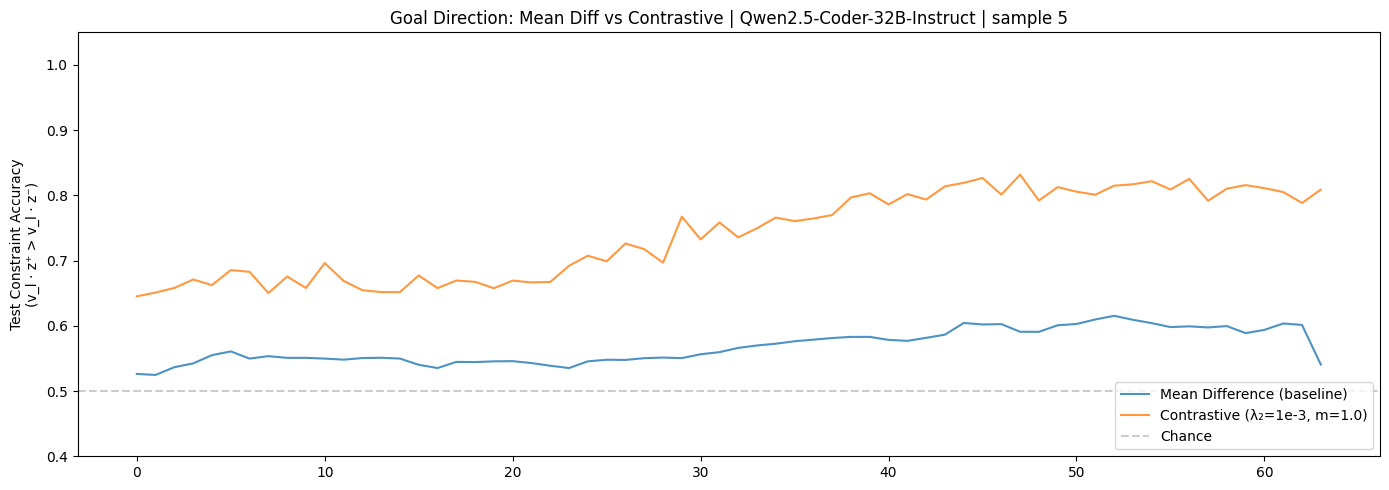

In [36]:

import matplotlib.pyplot as plt

with open(os.path.join(
    env_utils.DEFAULT_RESULTS_DIR, 
    ############################################################
    "probe_test_d=10", 
    ############################################################
    model_short_name, 
    f"sample_{SAMPLE_IDX}",
    "accuracies.json"
), "r") as f:
    accuracies = json.load(f)



layers_sorted = list(range(mt.n_layer))
md_test = [accuracies["mean_diff_test"][str(li)] for li in layers_sorted]
ct_test = [accuracies["contrastive_test"][str(li)] for li in layers_sorted]

reg_desc = ["λ₂=1e-3"]
MARGIN = 1.0
reg_label = ", ".join(reg_desc)

fig, axes = plt.subplots(1, 1, figsize=(14, 5), sharex=True)

# Top: accuracy comparison
ax = axes
ax.plot(layers_sorted, md_test, label="Mean Difference (baseline)", alpha=0.8, linewidth=1.5)
ax.plot(layers_sorted, ct_test, label=f"Contrastive ({reg_label}, m={MARGIN})", alpha=0.8, linewidth=1.5)
ax.axhline(y=0.5, color="gray", linestyle="--", alpha=0.4, label="Chance")
ax.set_ylabel("Test Constraint Accuracy\n(v_l · z⁺ > v_l · z⁻)")
ax.set_title(f"Goal Direction: Mean Diff vs Contrastive | {model_short_name} | sample {SAMPLE_IDX}")
ax.legend(loc="lower right")
ax.set_ylim(0.4, 1.05)

plt.tight_layout()
plt.show()

In [19]:

# --- Contrastive direction projection: computation ---
# Requires: contrastive_directions (from training cells below — run those first),
#           Z_pos_by_layer, Z_neg_by_layer, test_idx
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
import numpy as np

LAYER_FROM_CD = 0
LAYER_TO_CD = 64
LAYER_STEP_CD = 1
DO_NORMALIZE = True  # If True, L2-normalize latents before projection (cosine similarity).
                     # Isolates directional alignment from magnitude differences.

cd_layers = list(range(LAYER_FROM_CD, LAYER_TO_CD, LAYER_STEP_CD))
test_idx_arr = np.array(test_idx)

# Store results per layer
cd_proj_results: dict[int, dict] = {}

_orig_print(f"\n{'Layer':>6} {'AUC(goal)':>10} {'AUC(resid)':>11} {'Resid Var%':>10}")
_orig_print(f"{'-----':>6} {'---------':>10} {'----------':>11} {'---------':>10}")
for layer_idx in cd_layers:
    v = loaded_directions[layer_idx].cpu().numpy()  # (hidden_dim,), unit vector

    # Test-set latents only
    z_pos = Z_pos_by_layer[layer_idx][test_idx_arr].cpu().numpy()
    z_neg = Z_neg_by_layer[layer_idx][test_idx_arr].cpu().numpy()
    n_test = z_pos.shape[0]

    # Stack pos + neg
    all_z = np.concatenate([z_pos, z_neg], axis=0)  # (2*n_test, hidden_dim)

    # Normalize latents to unit vectors if requested
    if DO_NORMALIZE:
        norms = np.linalg.norm(all_z, axis=1, keepdims=True)
        norms = np.maximum(norms, 1e-8)  # avoid division by zero
        all_z = all_z / norms

    # Axis 1: projection onto contrastive direction
    proj_goal = all_z @ v  # (2*n_test,)

    # Residual: remove the component along v
    z_residual = all_z - np.outer(proj_goal, v)

    # Axis 2: top PCA component of the residual (fit on test set)
    pca_res = PCA(n_components=1)
    proj_residual = pca_res.fit_transform(z_residual).squeeze()  # (2*n_test,)

    # Separability metrics
    labels = np.concatenate([np.ones(n_test), np.zeros(n_test)])
    auc_goal = roc_auc_score(labels, proj_goal)
    auc_residual = roc_auc_score(labels, proj_residual)

    cd_proj_results[layer_idx] = {
        "pos_goal": proj_goal[:n_test],
        "neg_goal": proj_goal[n_test:],
        "pos_residual": proj_residual[:n_test],
        "neg_residual": proj_residual[n_test:],
        "residual_var_ratio": pca_res.explained_variance_ratio_[0],
        "auc_goal": auc_goal,
        "auc_residual": auc_residual,
    }

    results = cd_proj_results[layer_idx]
    _orig_print(f"{layer_idx:>6} {results['auc_goal']:>10.3f} {results['auc_residual']:>11.3f} {results['residual_var_ratio']:>9.1%}")

norm_label = "normalized" if DO_NORMALIZE else "unnormalized"
_orig_print(f"Computed contrastive projections for {len(cd_layers)} layers ({norm_label}, test set: {n_test} pos + {n_test} neg)")



 Layer  AUC(goal)  AUC(resid) Resid Var%
 -----  ---------  ----------  ---------


     0      0.718       0.480     23.7%
     1      0.767       0.486     24.3%
     2      0.880       0.486     24.9%
     3      0.865       0.488     25.1%
     4      0.863       0.486     23.4%
     5      0.906       0.484     22.3%
     6      0.913       0.484     21.6%
     7      0.862       0.512     24.4%
     8      0.936       0.512     23.3%
     9      0.929       0.512     22.6%
    10      0.932       0.511     20.8%
    11      0.913       0.512     19.0%
    12      0.891       0.488     18.5%
    13      0.913       0.513     17.9%
    14      0.904       0.521     17.8%
    15      0.912       0.520     18.2%
    16      0.907       0.518     18.2%
    17      0.910       0.515     18.3%
    18      0.909       0.512     18.0%
    19      0.912       0.513     17.9%
    20      0.888       0.515     17.5%
    21      0.908       0.512     17.4%
    22      0.900       0.512     17.3%
    23      0.926       0.515     17.1%
    24      0.923       0.515     16.9%


In [20]:

# --- Contrastive direction projection: animated visualization ---
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(8, 7))

# Precompute global axis limits across all layers for stable animation
all_goal = np.concatenate([np.concatenate([r["pos_goal"], r["neg_goal"]]) for r in cd_proj_results.values()])
all_resid = np.concatenate([np.concatenate([r["pos_residual"], r["neg_residual"]]) for r in cd_proj_results.values()])
pad_g = (all_goal.max() - all_goal.min()) * 0.05
pad_r = (all_resid.max() - all_resid.min()) * 0.05
xlim = (all_goal.min() - pad_g, all_goal.max() + pad_g)
ylim = (all_resid.min() - pad_r, all_resid.max() + pad_r)

neg_scatter = ax.scatter([], [], alpha=0.12, s=6, c="tab:red", label="Negative (fail)")
pos_scatter = ax.scatter([], [], alpha=0.12, s=6, c="tab:blue", label="Positive (pass)")
ax.legend(markerscale=4, loc="upper right")
ax.set_xlim(xlim)
ax.set_ylim(ylim)
title = ax.set_title("")

model_short = mt.name.split("/")[-1]

def update(frame_idx):
    layer_idx = cd_layers[frame_idx]
    r = cd_proj_results[layer_idx]
    pos_scatter.set_offsets(np.column_stack([r["pos_goal"], r["pos_residual"]]))
    neg_scatter.set_offsets(np.column_stack([r["neg_goal"], r["neg_residual"]]))
    ax.set_xlabel(f"Contrastive Goal Direction (AUC={r['auc_goal']:.3f})")
    ax.set_ylabel(f"Top Residual PC ({r['residual_var_ratio']:.1%} var, AUC={r['auc_residual']:.3f})")
    title.set_text(f"Layer {layer_idx} | {model_short} | Sample {SAMPLE_IDX} | Test set only")
    return pos_scatter, neg_scatter, title

anim = animation.FuncAnimation(fig, update, frames=range(0, len(cd_layers), 4), interval=200, blit=False)
anim.save(os.path.join(FIGURE_DIR, "contrastive.gif"), writer="pillow", fps=2, dpi=120) 

plt.close(fig)
HTML(anim.to_jshtml())


2026-02-19 15:42:40 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.PillowWriter'>
2026-02-19 15:42:43 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.HTMLWriter'>
2026-02-19 15:42:43 matplotlib.animation DEBUG    frame size in pixels is 800 x 700
2026-02-19 15:42:46 matplotlib.animation DEBUG    MovieWriter: clearing temporary path=<TemporaryDirectory '/tmp/tmp43386fnt'>


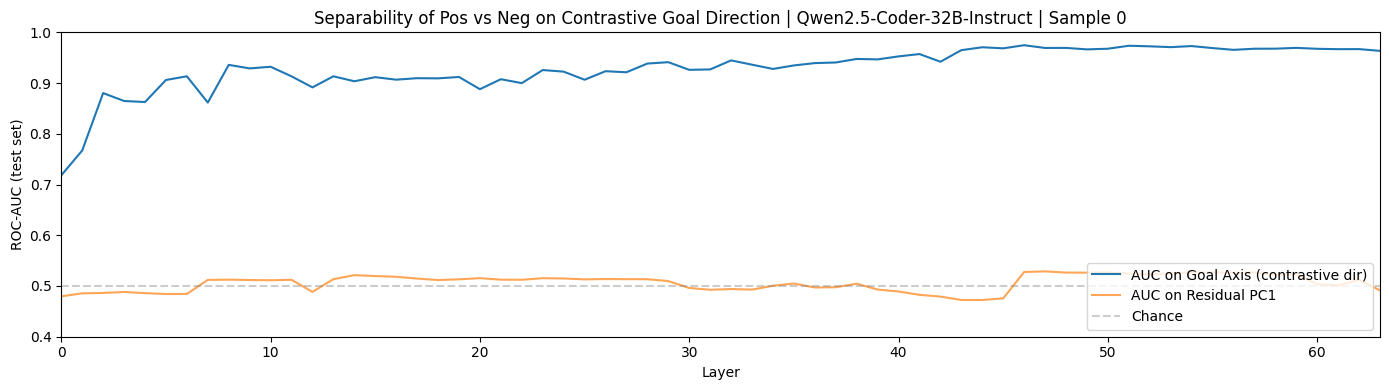

In [21]:

# --- AUC summary across layers ---
import matplotlib.pyplot as plt

layers_sorted = sorted(cd_proj_results.keys())
auc_goal_vals = [cd_proj_results[l]["auc_goal"] for l in layers_sorted]
auc_resid_vals = [cd_proj_results[l]["auc_residual"] for l in layers_sorted]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(layers_sorted, auc_goal_vals, label="AUC on Goal Axis (contrastive dir)", linewidth=1.5)
ax.plot(layers_sorted, auc_resid_vals, label="AUC on Residual PC1", linewidth=1.5, alpha=0.7)
ax.axhline(y=0.5, color="gray", linestyle="--", alpha=0.4, label="Chance")
ax.set_xlabel("Layer")
ax.set_ylabel("ROC-AUC (test set)")
ax.set_title(f"Separability of Pos vs Neg on Contrastive Goal Direction | {mt.name.split('/')[-1]} | Sample {SAMPLE_IDX}")
ax.legend(loc="lower right")
ax.set_ylim(0.4, 1.0)
ax.set_xlim(layers_sorted[0], layers_sorted[-1])
plt.tight_layout()
plt.show()


## Train goal directions

In [20]:
# --- 3) Baseline: mean difference goal direction per layer ---
# For each layer l independently, find a direction v_l such that v_l · z⁺ > v_l · z⁻
# Baseline: v_l = mean(z⁺_l) - mean(z⁻_l), normalized.
# Each layer gets its own independent goal direction, stored on that layer's device.
# train_idx / test_idx are from tree-level split (no latent leakage).

n_pairs = n_pairs_total
n_layers = len(LAYERS_TO_PROBE)

_orig_print(f"Train pairs: {len(train_idx)}, Test pairs: {len(test_idx)}")

# --- Compute and store goal direction per layer ---
goal_directions: dict[int, torch.Tensor] = {}   # layer -> (hidden_dim,) on layer's device
train_accuracies: dict[int, float] = {}
test_accuracies: dict[int, float] = {}

for layer_idx in LAYERS_TO_PROBE:
    z_pos_l = Z_pos_by_layer[layer_idx]  # (n_pairs, hidden_dim) on layer's device
    z_neg_l = Z_neg_by_layer[layer_idx]
    
    # Goal direction for this layer: mean difference on train set
    z_pos_train = z_pos_l[train_idx]
    z_neg_train = z_neg_l[train_idx]
    
    v_l = z_pos_train.mean(dim=0) - z_neg_train.mean(dim=0)
    v_l = v_l / (v_l.norm() + 1e-8)
    goal_directions[layer_idx] = v_l
    
    # Train accuracy: fraction of pairs where v_l · z⁺ > v_l · z⁻
    train_acc = (z_pos_train @ v_l > z_neg_train @ v_l).float().mean().item()
    train_accuracies[layer_idx] = train_acc
    
    # Test accuracy
    z_pos_test = z_pos_l[test_idx]
    z_neg_test = z_neg_l[test_idx]
    test_acc = (z_pos_test @ v_l > z_neg_test @ v_l).float().mean().item()
    test_accuracies[layer_idx] = test_acc

print(f"\ngoal_directions: {len(goal_directions)} layers, each on its native device")
print(f"\nConstraint accuracy (v_l · z⁺ > v_l · z⁻) per layer:")
print(f"{'Layer':>6} {'Train':>8} {'Test':>8} {'Device':>10}")
print(f"{'-----':>6} {'-----':>8} {'-----':>8} {'------':>10}")
for l in LAYERS_TO_PROBE:
    marker = " <--" if test_accuracies[l] >= 0.8 else ""
    _orig_print(f"{l:>6} {train_accuracies[l]:>8.3f} {test_accuracies[l]:>8.3f} {str(goal_directions[l].device):>10}{marker}")

Train pairs: 10000, Test pairs: 10526


goal_directions: 64 layers, each on its native device

Constraint accuracy (v_l · z⁺ > v_l · z⁻) per layer:

Layer    Train     Test     Device

-----    -----    -----     ------

     0    0.683    0.665     cuda:0
     1    0.685    0.667     cuda:0
     2    0.686    0.666     cuda:0
     3    0.700    0.680     cuda:0
     4    0.711    0.692     cuda:0
     5    0.720    0.698     cuda:0
     6    0.717    0.692     cuda:1
     7    0.712    0.687     cuda:1
     8    0.708    0.678     cuda:1
     9    0.709    0.681     cuda:1
    10    0.705    0.680     cuda:1
    11    0.714    0.684     cuda:1
    12    0.718    0.677     cuda:1
    13    0.723    0.677     cuda:1
    14    0.729    0.676     cuda:1
    15    0.738    0.676     cuda:2
    16    0.742    0.678     cuda:2
    17    0.744    0.677     cuda:2
    18    0.745    0.681     cuda:2
    19    0.745    0.676     cuda:2
    20    0.745    0.667     cuda:2
    21    0.744    0.659     cuda:2
    22    0.746    0.659     cuda:2
    23    0.750    0.662     cuda:2
    24    0.747    0.658     cuda:3
    25    0.746    0.662     cuda:3
    26    0.744    0.663     cuda:3
    27    0.746    0.669    

In [21]:
# --- Contrastive objective (Schut et al. Section 4.1.2) ---
# Find v_l that satisfies v_l · z⁺ ≥ v_l · z⁻ + margin.
# Objective: min  λ₁||v||₁ + λ₂||v||₂² + (1/N) Σᵢ max(0, margin - v·(z⁺ᵢ - z⁻ᵢ))
# Setting both lambdas to 0 gives pure hinge loss (no regularization).

@torch.enable_grad()
def learn_contrastive_direction(
    z_pos: torch.Tensor,       # (n_pairs, hidden_dim) on some device
    z_neg: torch.Tensor,       # (n_pairs, hidden_dim) on same device
    l1_lambda: float = 0.0,
    l2_lambda: float = 1e-3,
    margin: float = 1.0,
    lr: float = 1e-2,
    n_steps: int = 1000,
    patience: int = 50,
) -> tuple[torch.Tensor, dict]:
    """
    Learn a goal direction via the contrastive objective.
    
    Minimizes:  λ₁||v||₁ + λ₂||v||₂² + (1/N) Σᵢ max(0, margin - v·(z⁺ᵢ - z⁻ᵢ))
    
    - L1 encourages sparsity (neuron-basis assumption, strong).
    - L2 encourages small norm without basis assumptions.
    - Both at 0 = pure hinge loss, no regularization.
    
    Args:
        z_pos: Positive latents (n_pairs, hidden_dim)
        z_neg: Negative latents (n_pairs, hidden_dim)
        l1_lambda: L1 regularization strength (sparsity)
        l2_lambda: L2 regularization strength (norm penalty)
        margin: Hinge loss margin
        lr: Learning rate for Adam
        n_steps: Maximum optimization steps
        patience: Early stopping patience (steps without improvement)
    
    Returns:
        v: Normalized goal direction (hidden_dim,) on same device
        info: Dict with optimization stats
    """
    device = z_pos.device
    hidden_dim = z_pos.shape[1]
    
    # Precompute difference vectors
    delta = z_pos - z_neg  # (n_pairs, hidden_dim)
    
    # Initialize v with small random values
    v = torch.randn(hidden_dim, device=device, dtype=z_pos.dtype) * 0.01
    v.requires_grad_(True)
    
    optimizer = torch.optim.Adam([v], lr=lr)
    
    best_loss = float('inf')
    patience_counter = 0
    final_step = n_steps
    
    for step in range(n_steps):
        optimizer.zero_grad()
        
        scores = delta @ v                                    # (n_pairs,)
        hinge_loss = torch.clamp(margin - scores, min=0).mean()
        
        # Regularization terms (only computed if lambda > 0)
        reg_loss = torch.zeros(1, device=device, dtype=z_pos.dtype)
        if l1_lambda > 0:
            reg_loss = reg_loss + l1_lambda * v.abs().sum()
        if l2_lambda > 0:
            reg_loss = reg_loss + l2_lambda * (v @ v)         # ||v||₂²
        
        loss = hinge_loss + reg_loss.squeeze()
        
        loss.backward()
        optimizer.step()
        
        curr_loss = loss.item()
        if curr_loss < best_loss - 1e-6:
            best_loss = curr_loss
            patience_counter = 0
        else:
            patience_counter += 1
        
        if patience_counter >= patience:
            final_step = step + 1
            break
    
    with torch.no_grad():
        v_final = v.detach()
        v_norm = v_final.norm()
        v_normalized = v_final / (v_norm + 1e-8)
        
        # Stats
        scores_final = delta @ v_normalized
        constraint_sat = (scores_final > 0).float().mean().item()
        sparsity = (v_normalized.abs() < 1e-2).float().mean().item()
    
    return v_normalized, {
        "final_loss": best_loss,
        "steps": final_step,
        "constraint_satisfaction": constraint_sat,
        "sparsity": sparsity,
        "v_norm_pre_normalize": v_norm.item(),
    }


print("learn_contrastive_direction defined (with L1 + L2 regularization)")

learn_contrastive_direction defined (with L1 + L2 regularization)

In [22]:
# --- Run contrastive objective per layer ---
# Uses the same train/test split as the baseline.

L1_LAMBDA = 0.0     # sparsity (neuron-basis assumption); 0 = off
L2_LAMBDA = 1e-3    # norm penalty (basis-free); 0 = off
MARGIN = 1.0
LR = 1e-2
N_STEPS = 1000

contrastive_directions: dict[int, torch.Tensor] = {}
contrastive_train_accs: dict[int, float] = {}
contrastive_test_accs: dict[int, float] = {}
contrastive_infos: dict[int, dict] = {}

reg_desc = []
if L1_LAMBDA > 0: reg_desc.append(f"λ₁={L1_LAMBDA}")
if L2_LAMBDA > 0: reg_desc.append(f"λ₂={L2_LAMBDA}")
if not reg_desc: reg_desc.append("no regularization")
_orig_print(f"Learning contrastive directions for {n_layers} layers ({', '.join(reg_desc)}, margin={MARGIN})...")

for layer_idx in LAYERS_TO_PROBE:
    z_pos_l = Z_pos_by_layer[layer_idx]
    z_neg_l = Z_neg_by_layer[layer_idx]
    
    z_pos_train = z_pos_l[train_idx]
    z_neg_train = z_neg_l[train_idx]
    
    v_l, info = learn_contrastive_direction(
        z_pos_train, z_neg_train,
        l1_lambda=L1_LAMBDA, l2_lambda=L2_LAMBDA,
        margin=MARGIN, lr=LR, n_steps=N_STEPS,
    )
    contrastive_directions[layer_idx] = v_l
    contrastive_infos[layer_idx] = info
    
    # Train accuracy
    train_acc = (z_pos_train @ v_l > z_neg_train @ v_l).float().mean().item()
    contrastive_train_accs[layer_idx] = train_acc
    
    # Test accuracy
    z_pos_test = z_pos_l[test_idx]
    z_neg_test = z_neg_l[test_idx]
    test_acc = (z_pos_test @ v_l > z_neg_test @ v_l).float().mean().item()
    contrastive_test_accs[layer_idx] = test_acc
    
    if layer_idx % 10 == 0:
        _orig_print(f"  Layer {layer_idx:>3}: test_acc={test_acc:.3f}, steps={info['steps']}, sparsity={info['sparsity']:.3f}")

# --- Print comparison table ---
print(f"\n[bold]Comparison: Mean Difference vs Contrastive ({', '.join(reg_desc)})[/bold]")
print(f"{'Layer':>6} {'MeanDiff':>10} {'Contrastive':>12} {'Δ':>8} {'Steps':>6} {'Sparsity':>9}")
print(f"{'-----':>6} {'--------':>10} {'-----------':>12} {'--':>8} {'-----':>6} {'--------':>9}")
for l in LAYERS_TO_PROBE:
    md_acc = test_accuracies[l]
    ct_acc = contrastive_test_accs[l]
    delta = ct_acc - md_acc
    steps = contrastive_infos[l]["steps"]
    sparsity = contrastive_infos[l]["sparsity"]
    marker = " <--" if ct_acc >= 0.8 else ""
    _orig_print(f"{l:>6} {md_acc:>10.3f} {ct_acc:>12.3f} {delta:>+8.3f} {steps:>6} {sparsity:>9.3f}{marker}")

Learning contrastive directions for 64 layers (λ₂=0.001, margin=1.0)...
  Layer   0: test_acc=0.792, steps=539, sparsity=0.585
  Layer  10: test_acc=0.761, steps=477, sparsity=0.584
  Layer  20: test_acc=0.803, steps=213, sparsity=0.570
  Layer  30: test_acc=0.854, steps=588, sparsity=0.571
  Layer  40: test_acc=0.878, steps=652, sparsity=0.567
  Layer  50: test_acc=0.908, steps=1000, sparsity=0.531
  Layer  60: test_acc=0.888, steps=1000, sparsity=0.562


Comparison: Mean Difference vs Contrastive (λ₂=0.001)

Layer   MeanDiff  Contrastive        Δ  Steps  Sparsity

-----   --------  -----------       --  -----  --------

     0      0.665        0.792   +0.128    539     0.585
     1      0.667        0.763   +0.096    338     0.593
     2      0.666        0.772   +0.106    462     0.582
     3      0.680        0.788   +0.108    247     0.576
     4      0.692        0.759   +0.067    247     0.580
     5      0.698        0.778   +0.080    312     0.560
     6      0.692        0.767   +0.075    599     0.578
     7      0.687        0.774   +0.087    218     0.610
     8      0.678        0.772   +0.094    475     0.582
     9      0.681        0.773   +0.092    354     0.595
    10      0.680        0.761   +0.081    477     0.584
    11      0.684        0.766   +0.081    373     0.584
    12      0.677        0.784   +0.107    263     0.568
    13      0.677        0.796   +0.119    324     0.599
    14      0.676        0.785   +0.108    398     0.570
    15      0.676        0.801   +0.126    179     0.563 <--
    16      0.678        0.796   +0.118    225     0.578
    17      0.677        0.

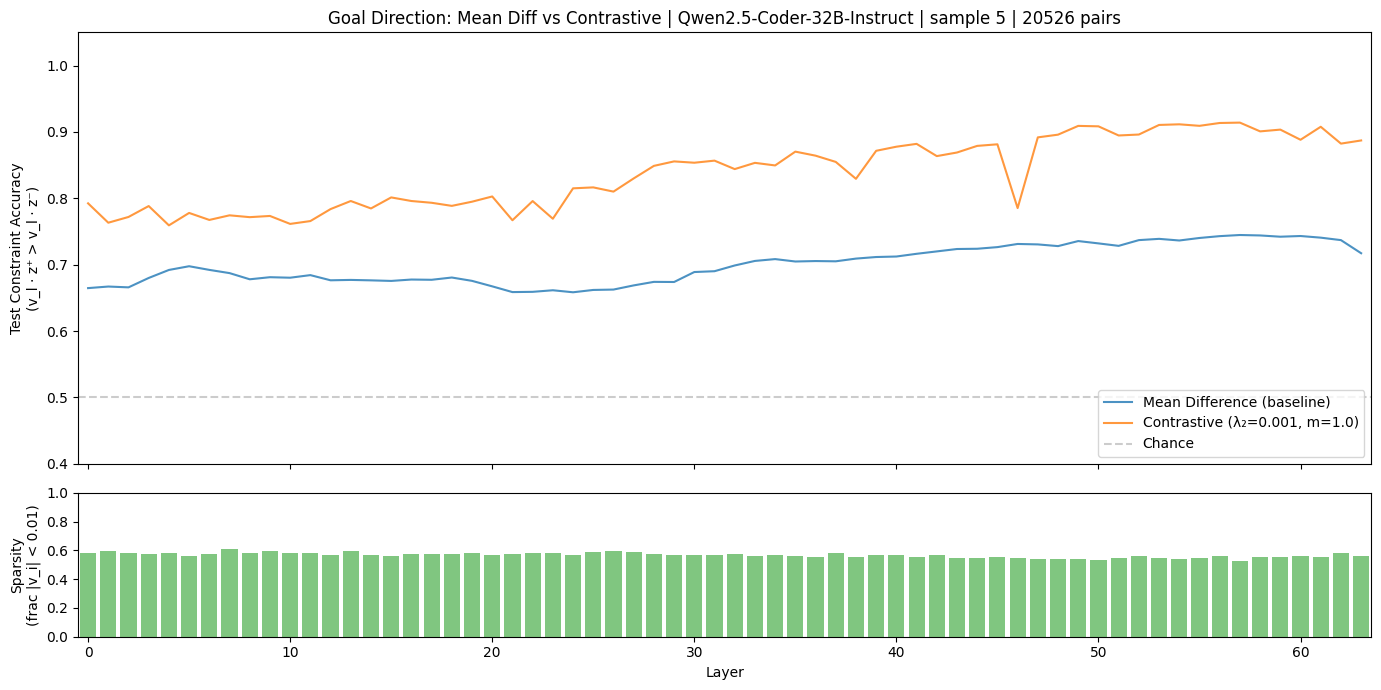

In [ ]:
# --- Plot: Mean Difference vs Contrastive Objective ---
import matplotlib.pyplot as plt

layers_sorted = sorted(LAYERS_TO_PROBE)

md_test = [test_accuracies[l] for l in layers_sorted]
ct_test = [contrastive_test_accs[l] for l in layers_sorted]
ct_sparsity = [contrastive_infos[l]["sparsity"] for l in layers_sorted]

reg_label = ", ".join(reg_desc)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), gridspec_kw={"height_ratios": [3, 1]}, sharex=True)

# Top: accuracy comparison
ax = axes[0]
ax.plot(layers_sorted, md_test, label="Mean Difference (baseline)", alpha=0.8, linewidth=1.5)
ax.plot(layers_sorted, ct_test, label=f"Contrastive ({reg_label}, m={MARGIN})", alpha=0.8, linewidth=1.5)
ax.axhline(y=0.5, color="gray", linestyle="--", alpha=0.4, label="Chance")
ax.set_ylabel("Test Constraint Accuracy\n(v_l · z⁺ > v_l · z⁻)")
ax.set_title(f"Goal Direction: Mean Diff vs Contrastive | {model_short_name} | sample {SAMPLE_IDX} | {n_pairs} pairs")
ax.legend(loc="lower right")
ax.set_ylim(0.4, 1.05)

# Bottom: sparsity of contrastive directions
ax2 = axes[1]
ax2.bar(layers_sorted, ct_sparsity, alpha=0.6, color="tab:green", width=0.8)
ax2.set_xlabel("Layer")
ax2.set_ylabel("Sparsity\n(frac |v_i| < 0.01)")
ax2.set_ylim(0, 1)
ax2.set_xlim(layers_sorted[0] - 0.5, layers_sorted[-1] + 0.5)

plt.tight_layout()
plt.show()

In [24]:
torch.save(contrastive_directions, os.path.join(save_dir, "contrastive_directions.pt"))
torch.save(goal_directions, os.path.join(save_dir, "mean_diff_directions.pt"))

with open(os.path.join(save_dir, "contrastive_infos.json"), "w") as f:
    json.dump(contrastive_infos, f, indent=2)

with open(os.path.join(save_dir, "test_accuracies.json"), "w") as f:
    json.dump({
        "mean_diff": test_accuracies,
        "contrastive": contrastive_test_accs,
    }, f, indent=2)

## Test $\mathrm{causality}$

In [7]:
from src.goals.data import IncompleteCodeDataset
from rich.console import Console
from rich.table import Table
from rich.text import Text
from rich import box

eval_dataset = IncompleteCodeDataset.load_dataset()
with open(os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "causality_unique",
    model_key.split("/")[-1],  
    "causality_results.json"
), "r") as f:
    steering_summary = json.load(f)

console = Console()

def fmt_rate(r):
    if r is None:
        return "[dim]N/A[/dim]"
    return f"{r:.2f}"

def fmt_coeff(c):
    if c is None:
        return "[dim]N/A[/dim]"
    return f"{c:.3f}"

def fmt_delta(baseline, rate):
    if rate is None or baseline is None:
        return "[dim]N/A[/dim]"
    delta = rate - baseline
    if delta > 0.005:
        return f"[green]+{delta:.2f}[/green]"
    elif delta < -0.005:
        return f"[red]{delta:.2f}[/red]"
    else:
        return f"{delta:.2f}"

for sample_idx_str, sample_data in steering_summary.items():
    sample_idx = int(sample_idx_str)
    function_name = sample_data["function_name"]
    layer_from = sample_data["layer_from"]
    layer_to = sample_data["layer_to"]
    n_generations = sample_data["n_generations"]
    prefill_results = sample_data["prefill_results"]

    sample = eval_dataset[sample_idx]
    code_snippet = sample.code.strip()

    console.rule(f"[bold cyan]Sample {sample_idx}: {function_name}[/bold cyan]  [dim](layers {layer_from}–{layer_to}, n={n_generations})[/dim]")
    console.print(f"[dim]{code_snippet}[/dim]\n")

    table = Table(box=box.SIMPLE_HEAVY, show_header=True, header_style="bold white")
    table.add_column("Prefill", style="bold yellow", no_wrap=True)
    table.add_column("Baseline", justify="right")
    table.add_column("Contr. Rate", justify="right")
    table.add_column("Contr. Coeff", justify="right")
    table.add_column("Δ Contr.", justify="right")
    table.add_column("MeanDiff Rate", justify="right")
    table.add_column("MeanDiff Coeff", justify="right")
    table.add_column("Δ MeanDiff", justify="right")

    for prefill, pr in prefill_results.items():
        baseline = float(pr.get("baseline_pass_rate"))
        best_contr_rate = float(pr.get("best_contrastive_pass_rate"))
        best_contr_coeff = float(pr.get("best_contrastive_coeff"))
        best_md_rate = float(pr.get("best_mean_diff_pass_rate"))
        best_md_coeff = float(pr.get("best_mean_diff_coeff"))

        table.add_row(
            repr(prefill),
            fmt_rate(baseline),
            fmt_rate(best_contr_rate),
            fmt_coeff(best_contr_coeff),
            fmt_delta(baseline, best_contr_rate),
            fmt_rate(best_md_rate),
            fmt_coeff(best_md_coeff),
            fmt_delta(baseline, best_md_rate),
        )

    console.print(table)
    # console.print()


2026-02-26 13:44:31 src.goals.data INFO     Loaded 14 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json


───────────────────────────────────── Sample 0: is_odd  (layers 40–50, n=100) ─────────────────────────────────────

def is_odd(n: int) -> bool:
    return True if

 Prefill   Baseline   Contr. Rate   Contr. Coeff   Δ Contr.   MeanDiff Rate   MeanDiff Coeff   Δ MeanDiff  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  '(3'          0.00          0.00          0.020       0.00            0.00            0.020         0.00  
  '1 -'         0.00          0.07          0.020      +0.07            0.05            0.020        +0.05  
  '5'           0.00          0.16          0.140      +0.16            0.00            0.020         0.00  
  '3 +'         0.00          0.00          0.020       0.00            0.00            0.020         0.00

──────────────────────────────────── Sample 1: is_even  (layers 40–50, n=100) ─────────────────────────────────────

def is_even(n: int) -> bool:
    return True if

... (33 outputs left out)

 Prefill   Baseline   Contr. Rate   Contr. Coeff   Δ Contr.   MeanDiff Rate   MeanDiff Coeff   Δ MeanDiff  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  '(3'          0.00          0.04          0.040      +0.04            0.03            0.020        +0.03  
  '1 -'         0.00          0.00          0.020       0.00            0.00            0.020         0.00  
  '5'           0.11          0.03          0.020      -0.08            0.00            0.020        -0.11  
  '3 +'         0.07          0.00          0.020      -0.07            0.00            0.020        -0.07

─────────────────────────────────── Sample 13: all_same  (layers 40–50, n=100) ────────────────────────────────────

def all_same(lst: list) -> bool:
    return True if

 Prefill   Baseline   Contr. Rate   Contr. Coeff   Δ Contr.   MeanDiff Rate   MeanDiff Coeff   Δ MeanDiff  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  '(3'          0.19          0.27          0.040      +0.08            0.12            0.020        -0.07  
  '1 -'         0.37          1.00          0.080      +0.63            0.68            0.060        +0.31  
  '5'           0.06          0.04          0.020      -0.02            0.01            0.020        -0.05  
  '3 +'         0.48          1.00          0.040      +0.52            0.68            0.040        +0.20

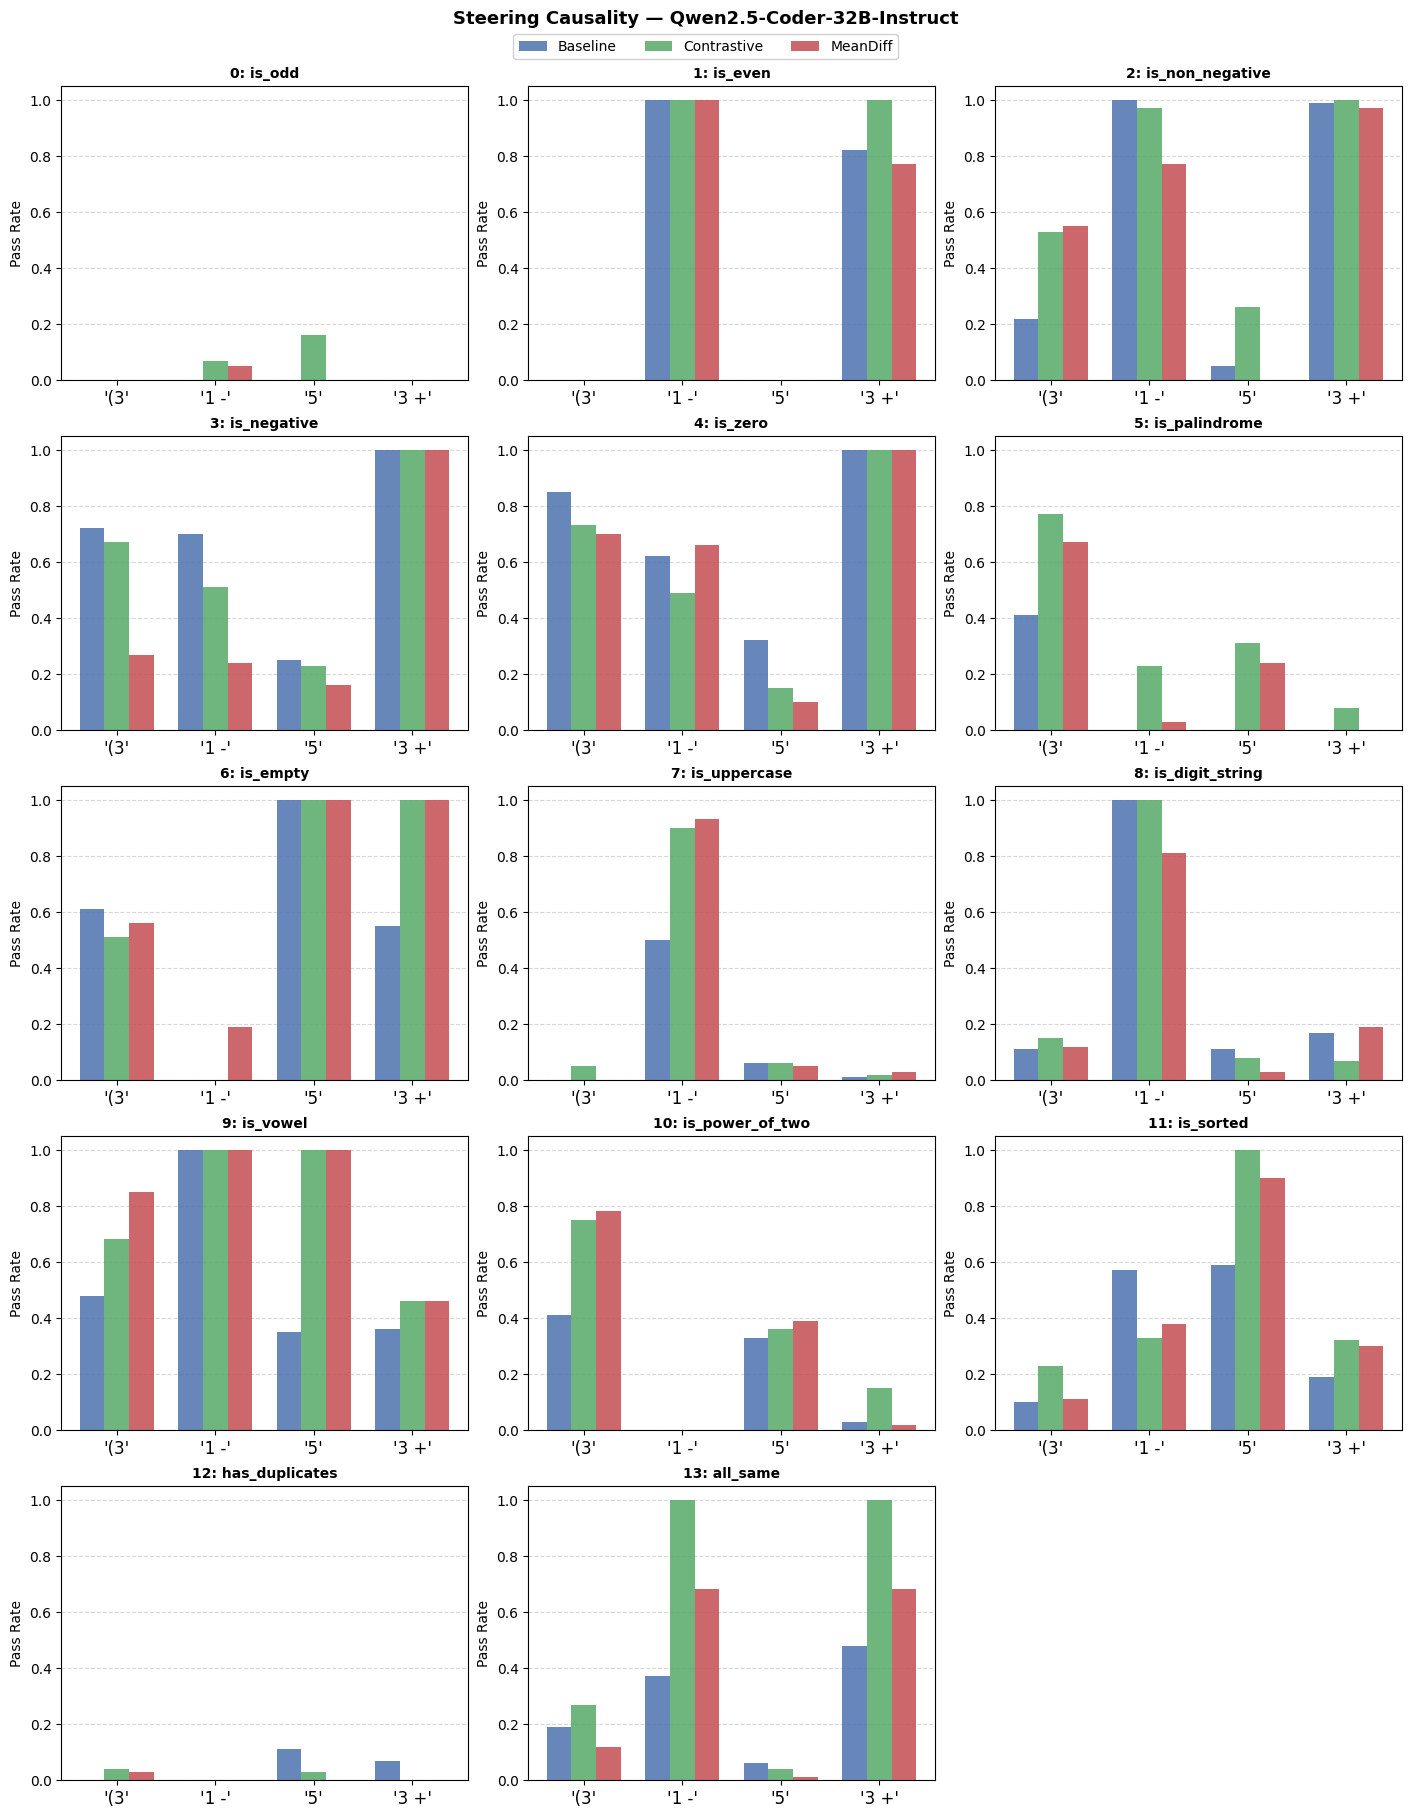

In [9]:
import matplotlib.pyplot as plt
import numpy as np

n_samples = len(steering_summary)
n_cols = 3
n_rows = (n_samples + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 3.5), constrained_layout=True)
axes = axes.flatten()

bar_width = 0.25
colors = {"Baseline": "#4C72B0", "Contrastive": "#55A868", "MeanDiff": "#C44E52"}

for ax_idx, (sample_idx_str, sample_data) in enumerate(steering_summary.items()):
    ax = axes[ax_idx]
    function_name = sample_data["function_name"]
    prefill_results = sample_data["prefill_results"]

    prefills = list(prefill_results.keys())
    x = np.arange(len(prefills))

    baselines  = [pr.get("baseline_pass_rate")         or 0.0 for pr in prefill_results.values()]
    contr      = [pr.get("best_contrastive_pass_rate") or 0.0 for pr in prefill_results.values()]
    meandiff   = [pr.get("best_mean_diff_pass_rate")   or 0.0 for pr in prefill_results.values()]

    ax.bar(x - bar_width, baselines, bar_width, label="Baseline",    color=colors["Baseline"],    alpha=0.85)
    ax.bar(x,             contr,     bar_width, label="Contrastive", color=colors["Contrastive"], alpha=0.85)
    ax.bar(x + bar_width, meandiff,  bar_width, label="MeanDiff",    color=colors["MeanDiff"],    alpha=0.85)

    ax.set_title(f"{sample_idx_str}: {function_name}", fontsize=10, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels([repr(p) for p in prefills], fontsize=12)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Pass Rate")
    ax.yaxis.grid(True, linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

for ax in axes[n_samples:]:
    ax.set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle(f"Steering Causality — {model_key.split('/')[-1]}", fontsize=13, fontweight="bold", y=1.03)
fig.legend(handles, labels, loc="upper center", ncol=len(labels), fontsize=10, framealpha=0.9,
           bbox_to_anchor=(0.5, 1.02), bbox_transform=fig.transFigure)
plt.show()


In [11]:
from src.goals.functional import supports_chat_template, apply_chat_template
from src.goals.data import IncompleteCodeDataset


SAMPLE_IDX = 5

eval_dataset = IncompleteCodeDataset.load_dataset()
sample = eval_dataset[SAMPLE_IDX]
rich_print(sample)

# prefill = "(3"
# prefill = "0 =="
# prefill = "1 +"
prefill = "1 -"
# prefill = "1 - len(s)"
# prefill = "1"
# prefill = ""
# prefill = "5"
# prefill = "("
# prefill = "3 +"

if supports_chat_template(mt):
    prompt = apply_chat_template(
        mt=mt,
        user_query=sample.instruction.strip(),
        incomplete_code=sample.code + prefill,
    )
else:
    prompt = sample.instruction + "<code>" + sample.code + prefill

print(f"Prompt:\n{prompt}")

2026-02-26 13:45:26 src.goals.data INFO     Loaded 14 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json


IncompleteCodeSample(
    instruction='Write a function in python that checks if a string is a palindrome.\n\n',
    code='def is_palindrome(s: str) -> bool:\n    return True if ',
    unit_tests=[
        ('racecar', True),
        ('hello', False),
        ('', True),
        ('a', True),
        ('ab', False),
        ('aba', True),
        ('abba', True)
    ],
    prefills={
        'aligned': ['', '(', 's', 's ==', 's == s', 's[::', 's[::-1]', '(s', 'list(', 'list(s)'],
        'adversarial': ['not', 'not (', 's +', '3', '1 +'],
        'inconsequential': ['bool(', 'True and', 'False or', '0 +']
    },
    function_name='is_palindrome'
)

Prompt:
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if a string is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def is_palindrome(s: str) -> bool:
    return True if 1 -


In [13]:
from src.functional import generate_with_patch, get_hs
from src.tokens import prepare_input

tokenized = prepare_input(
    prompts=prompt,
    tokenizer=mt,
)

hs = get_hs(
    mt=mt,
    input=tokenized,
    locations=[(layer_name, -1) for layer_name in mt.layer_names],
)

orig_outputs = generate_with_patch(
    mt=mt,
    inputs=prompt,
    patches=None,
    do_sample=True,
    n_gen_per_prompt=100,
    remove_prefix=True,
    max_new_tokens=32,
)

# print("Original generations:")
# for gen in orig_outputs:
#     print(f'"  {gen}"')
#     print("-" * 50)

In [14]:
from src.goals.data import CodeGenerations, Code
from src.goals.eval import run_evaluation, pretty_print_eval_results

orig_generations = CodeGenerations(
    sample=sample,
    generations=[
        Code(
            prefill=prefill,
            prefill_type="manual",
            full_prompt=prompt,
            lm_generation=gen,
        )
        for gen in orig_outputs
    ],
)

orig_eval_results = run_evaluation(
    result=orig_generations,
    function_name=sample.function_name,
    code_stop_tag="</code>",
)

pretty_print_eval_results(orig_eval_results)

"""def is_palindrome(s: str) -> bool:
    return True if """

                                                                      Code Completion Results                                                                      
┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill       ┃ Logic                                                           ┃ Verdict ┃ Unit Tests                                                   ┃ Logs ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ manual: "1 -" │ "1 - len(s) <= s[::-1].find(s) <= 0 else False"                 │ FAILED  │ is_palindrome(racecar)=True ✓                                │      │
│               │                                                                 │         │ is_palindrome(hello)=True, expected False ✗                  │      │
│               │                                                                 │         │ is_palindrome()=False, expected True ✗                       │      │
│               │                                                                 │         │ is_palindrome(a)=True ✓                                      │      │
│               │                                                                 │         │ is_palindrome(ab)=True, expected False ✗                     │      │
│               │                                                                 │         │ is_palindrome(aba)=True ✓                                    │      │
│               │                                                                 │         │ is_palindrome(abba)=True ✓                                   │      │
├───────────────┼─────────────────────────────────────────────────────────────────┼─────────┼──────────────────────────────────────────────────────────────┼──────┤
│ manual: "1 -" │ "1 - len(s) <= 0 else s[0] == s[-1] and is_palindrome(s[1:-1])" │ FAILED  │ is_palindrome(racecar)=True ✓                                │      │
│               │                                                                 │         │ is_palindrome(hello)=True, expected False ✗                  │      │
│               │                                                                 │         │ is_palindrome() raised IndexError: string index out of range │      │
│               │                                                                 │         │ is_palindrome(a)=True ✓                                      │      │
│               │                                                                 │         │ is_palindrome(ab)=True, expected False ✗                     │      │
│               │                                                                 │         │ is_palindrome(aba)=True ✓                                    │      │
│               │                                                                 │         │ is_palindrome(abba)=True ✓                                   │      │
├───────────────┼─────────────────────────────────────────────────────────────────┼─────────┼──────────────────────────────────────────────────────────────┼──────┤
│ manual: "1 -" │ "1 - len(s) <= s.find(s[::-1]) <= 0 else False"                 │ FAILED  │ is_palindrome(racecar)=True ✓                                │      │
│               │                                                                 │         │ is_palindrome(hello)=True, expected False ✗                  │      │
│               │                                                                 │         │ is_palindrome()=False, expected True ✗                       │      │
│               │                                                                 │         │ is_palindrome(a)=True ✓                                      │      │
│               │                                               

Summary: 1/100 passed, 99/100 failed

In [15]:
# orig_generations.generations[0].eval.unit_test_results

In [27]:
from src.functional import PatchSpec

model_short_name = mt.name.split("/")[-1]
save_dir = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    ############################################################
    "probes_unique",
    ############################################################
    model_short_name,
    f"sample_{SAMPLE_IDX}",
)

loaded_directions = torch.load(
    os.path.join(
        save_dir,
        "contrastive_directions.pt",
        # "mean_diff_directions.pt"
    ),
    map_location="cuda:0",
)

layer_from = 40
layer_to = 50

#! seems to vary per task. probably related to the number of tokens being generated or processed (?)
coeff = 0.08

steer_directions = []

for layer_idx in range(layer_from, layer_to):
    layer_name = mt.layer_name_format.format(layer_idx)
    h_orig = hs[(layer_name, -1)]
    goal_dir = loaded_directions[layer_idx].to(h_orig.device)
    scaled_goal_dir = goal_dir * coeff * (h_orig.norm() / goal_dir.norm())

    print(
        f"layer={layer_idx} >> |h_orig|={h_orig.norm()}, |goal_dir|={goal_dir.norm()}, |scaled|={scaled_goal_dir.norm()}"
    )

    steer_directions.append(
        PatchSpec(
            location=(layer_name, -1),
            patch=scaled_goal_dir,
            strategy="add",
            on_pass="all", # all generations.
        )
    )


layer=40 >> |h_orig|=298.0, |goal_dir|=0.9999999403953552, |scaled|=23.84000015258789
layer=41 >> |h_orig|=306.0, |goal_dir|=1.0, |scaled|=24.48000144958496
layer=42 >> |h_orig|=304.0, |goal_dir|=1.0000001192092896, |scaled|=24.319997787475586
layer=43 >> |h_orig|=310.0, |goal_dir|=1.0, |scaled|=24.799999237060547
layer=44 >> |h_orig|=314.0, |goal_dir|=1.0, |scaled|=25.119997024536133
layer=45 >> |h_orig|=322.0, |goal_dir|=1.0000001192092896, |scaled|=25.760000228881836
layer=46 >> |h_orig|=342.0, |goal_dir|=1.0, |scaled|=27.35999870300293
layer=47 >> |h_orig|=364.0, |goal_dir|=1.0, |scaled|=29.119998931884766
layer=48 >> |h_orig|=380.0, |goal_dir|=1.0, |scaled|=30.39999771118164
layer=49 >> |h_orig|=416.0, |goal_dir|=1.0, |scaled|=33.279998779296875


In [28]:
from scripts.test_causality import generate_and_evaluate, save_eval_table

eval_results = generate_and_evaluate(
    mt=mt,
    sample=sample,
    prefill=prefill,
    prompt=prompt,
    n_generations=100,
    patches = steer_directions,
    label = "testing"
)

# failed_codes = [code for code in eval_results.generations if code.eval.verdict == "FAILED"]
# print(len(failed_codes))
# print(failed_codes[0])

2026-02-26 13:48:28 scripts.test_causality DEBUG    Generating 100 samples (testing)...


2026-02-26 13:48:35 scripts.test_causality DEBUG    Generation done. Evaluating 100 outputs...
2026-02-26 13:48:35 scripts.test_causality DEBUG    Evaluation done: 20/100 passed (0.200)


In [29]:
# from src.goals.eval import evaluate_single_code

# full_code = """def is_uppercase(s: str) -> bool:
#     return True if 1==2 else s.isalpha"""

# single_eval = evaluate_single_code(
#     full_code = full_code,
#     unit_tests= sample.unit_tests,
#     function_name=sample.function_name,
# )

# print(single_eval)

In [30]:
# str(failed_codes[0].eval.unit_test_results[0].actual)
eval_results.generations[0].eval.verdict

'FAILED'

In [31]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results.generations if gen.eval.verdict == "PASSED"
]
pretty_print_eval_results(eval_results_filtered)

"""def is_palindrome(s: str) -> bool:
    return True if """

                                                Code Completion Results                                                 
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill              ┃ Logic                                                           ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "1 -" │ "1 - len(s) == (len(s) - 1) else s == s[::-1]"                  │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s) == (len(s) - 1) else s == s[::-1]"                  │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s) == -len(s) else s == s[::-1]"                       │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s) == (len(s) - 1) else s == s[::-1]"                  │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s) >= 0 else s[0] == s[-1] and is_palindrome(s[1:-1])" │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s) == -len(s) else s == s[::-1]"                       │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s) == (len(s) - 1) else s == s[::-1]"                  │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s) == (len(s) - 1) else s == s[::-1]"                  │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s) == (len(s) - 1) else s == s[::-1]"                  │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s) >= 0 else s[0] == s[-1] and is_palindrome(s[1:-1])" │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s) >= 0 else s == s[::-1]"                             │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s) == (len(s) * -1) else s == s[::-1]"                 │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s) == (len(s) - 1) else s == s[::-1]"                  │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s) >= 0 else s[0] == s[-1] and is_palindrome(s[1:-1])" │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s) >= 0 else s[0] == s[-1] and is_palindrome(s[1:-1])" │ PASSED  │            │      │
├──────

Summary: 20/100 passed, 80/100 failed

In [57]:
# save_eval_table(
#     eval_results=eval_results,
#     filepath="test/test.json"
# )

In [14]:
# for layer_idx in range(40, 50):
#     v = loaded_directions[layer_idx]
#     h = hs[(mt.layer_name_format.format(layer_idx), -1)]
#     scale = h.norm() / v.norm()
#     print(
#         f"layer {layer_idx}: device={v.device}, norm={v.norm():.6f}, "
#         f"h_norm={h.norm():.4f}, scale={scale:.4f}, "
#         f"has_nan={v.isnan().any().item()}, has_inf={v.isinf().any().item()}"
#     )

In [ ]:
# patched_outputs = generate_with_patch(
#     mt=mt,
#     inputs=prompt,
#     patches=steer_directions,   # strategy + on_pass are set per-PatchSpec
#     do_sample=True,
#     n_gen_per_prompt=100,
#     remove_prefix=True,
#     max_new_tokens=32,
# )

# # print("Patched generations:")
# # for gen in patched_outputs:
# #     print(f'"  {gen}"')
# #     print("-" * 50)

In [58]:
# patch_generations = CodeGenerations(
#     sample=sample,
#     generations=[
#         Code(
#             prefill=prefill,
#             prefill_type="manual",
#             full_prompt=prompt,
#             lm_generation=gen,
#         )
#         for gen in patched_outputs
#     ],
# )

# patch_eval_results = run_evaluation(
#     result=patch_generations,
#     function_name=sample.function_name,
#     code_stop_tag="</code>",
# )

# pretty_print_eval_results(patch_eval_results)

In [ ]:
from src.functional import logit_lens

for layer_idx in range(layer_from, layer_to):
    h = hs[(mt.layer_name_format.format(layer_idx), -1)]
    direction = loaded_directions[layer_idx].to(mt.dtype).to(h.device)
    direction = direction * (h.norm() / direction.norm())
    ll_goal = logit_lens(
        mt=mt,
        h=direction,
    )
    print(f"{layer_idx}: {[str(pred) for pred in ll_goal]}")

35: ['".isAuthenticated"[73528] (p=0.019, logit=11.938)', '"事业"[100701] (p=0.013, logit=11.562)', '" EVT"[93257] (p=0.012, logit=11.438)', '"abis"[15367] (p=0.012, logit=11.438)', '"盗"[100591] (p=0.010, logit=11.312)']
36: ['".splitContainer"[38701] (p=0.082, logit=13.250)', '"斩获"[118841] (p=0.027, logit=12.125)', '".isAuthenticated"[73528] (p=0.016, logit=11.625)', '"Boost"[52363] (p=0.012, logit=11.312)', '"urf"[29363] (p=0.010, logit=11.125)']
37: ['"汩"[119751] (p=0.021, logit=11.625)', '"韧"[101843] (p=0.017, logit=11.375)', '" Maker"[40528] (p=0.011, logit=10.938)', '"谤"[119445] (p=0.010, logit=10.875)', '"_SRV"[95990] (p=0.008, logit=10.688)']
38: ['"不管你"[115860] (p=0.025, logit=11.688)', '".cgi"[59014] (p=0.023, logit=11.625)', '"aq"[36306] (p=0.012, logit=11.000)', '"楫"[121144] (p=0.010, logit=10.812)', '"unks"[15296] (p=0.009, logit=10.688)']
39: ['"wards"[4014] (p=0.098, logit=13.250)', '"peration"[91774] (p=0.043, logit=12.438)', '"_DA"[75144] (p=0.028, logit=12.000)', '"yer"

In [32]:
# SAMPLE_IDX = 0

# eval_dataset = IncompleteCodeDataset.load_dataset()
# sample = eval_dataset[SAMPLE_IDX]
# print(sample)

In [33]:
# from src.goals.eval import evaluate_single_code

# code = """def is_odd(n):
#     return True if 1 + (n & 1) else False"""

# print(evaluate_single_code(
#     full_code=code,
#     function_name="is_odd",
#     unit_tests=sample.unit_tests
# ))


In [ ]:
# generate_with_patch tests have been moved to a standalone script.
# Run from the project root:
#
#   conda run -n goals python test/test_generate_with_patch.py